# Notebook 05: Agent-Based Models

**Paper Reference:** Gould et al. (2013), Sections 5.1–5.3

This notebook compares three models of increasing sophistication:
1. **Smith et al. (2003)** — zero intelligence: independent Poisson order flow, uniform placement
2. **Mike & Farmer (2008), simplified** — power-law relative prices, long-memory order signs, log-normal sizes
3. **Parlour (1998)-inspired** — a hand-tuned rule in which traders choose between market and limit orders based on the spread and the queue at the best quotes

and measures which stylized facts each one reproduces. Every entry in the scorecard is computed from the simulations, using the criteria stated in Section 4.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from lob.book import OrderBook
from lob.order import Side, limit_order, reset_order_id_counter
from lob.simulation import Simulation, SimulationConfig
from lob.models.zero_intelligence import SmithFarmerModel
from lob.models.mike_farmer import MikeFarmerModel
from lob.models.strategic import ParlourModel
from lob.metrics import event_time_returns, mean_virtual_impact
from lob.analysis.stylized_facts import (
    compute_acf, compute_rank_volatility_acf, fit_loglog_slope,
    mean_depth_profile, classify_depth_profile,
)
from lob.analysis.plotting import set_style, plot_return_distribution, plot_acf

set_style()
pd.set_option('display.max_colwidth', None)

MODELS = {
    'ZI (Smith et al.)': lambda: SmithFarmerModel(
        mu=1.0, lam=0.5, delta=0.1, price_range=50, initial_mid=10000),
    'Mike-Farmer': lambda: MikeFarmerModel(
        mu=1.0, lam=2.0, delta=0.05, alpha_price=1.5, hurst=0.7,
        initial_mid=10000, size_mean=0.5, size_sigma=0.3),
    'Parlour (Strategic)': lambda: ParlourModel(
        arrival_rate=5.0, delta=0.05, spread_threshold=5, depth_threshold=10, initial_mid=10000),
}
SEEDS = [1, 2, 3, 4]
N_EVENTS = 400_000
K = 1_000  # events per return interval

## 1. Run All Three Models

Each model runs for 400,000 events after warm-up with four independent seeds, recording a book snapshot every 400 events. Returns are log mid-price returns over blocks of $K$ = 1,000 events: as Notebook 03 shows, returns over a handful of events are mostly exact zeros, which distorts their statistics.

In [2]:
def measure(make_model, seed):
    """Run one model with one seed and compute every statistic used below."""
    reset_order_id_counter()
    config = SimulationConfig(n_events=N_EVENTS, warmup_events=5_000, seed=seed,
                              record_book_snapshots=True, snapshot_interval=400)
    sim = Simulation(model=make_model(), config=config)
    df = sim.run(progress=False)
    valid = df.dropna(subset=['mid_price'])

    returns = event_time_returns(valid['mid_price'], K)
    signs = np.where(df.loc[df['event_type'] != 'cancel', 'side'] == 'bid', 1.0, -1.0)
    trades = df[(df['event_type'] == 'market') & (df['n_fills'] > 0)]
    trade_prices = np.array([prices[-1] for prices in trades['fill_prices']], dtype=float)
    _, bid_depth, ask_depth = mean_depth_profile(sim.snapshots, n_ticks=20)
    impact_sizes, impact = mean_virtual_impact(sim.snapshots, np.arange(1, 61))

    return {
        'df': df if seed == SEEDS[0] else None,  # keep one event log for plots
        'returns': returns,
        'mean_spread': valid['spread'].mean(),
        'kurtosis': stats.kurtosis(returns),
        'zero_returns': np.mean(returns == 0),
        'rank_acf_lag1': compute_rank_volatility_acf(returns, 1)[1],
        'sign_acf_lag100': compute_acf(signs, 100)[100],
        'bounce_acf_lag1': compute_acf(np.diff(trade_prices), 1)[1],
        'depth_profile': (bid_depth + ask_depth) / 2,
        'impact_sizes': impact_sizes,
        'impact': impact,
    }


results = {name: [measure(make, seed) for seed in SEEDS] for name, make in MODELS.items()}

for name, runs in results.items():
    print(f"{name:20s} mean spread {np.mean([r['mean_spread'] for r in runs]):.2f} ticks; "
          f"{len(runs[0]['returns'])} returns per seed, {np.mean([r['zero_returns'] for r in runs]):.0%} of them zero")

ZI (Smith et al.)    mean spread 1.33 ticks; 399 returns per seed, 26% of them zero
Mike-Farmer          mean spread 2.50 ticks; 375 returns per seed, 2% of them zero
Parlour (Strategic)  mean spread 2.19 ticks; 399 returns per seed, 4% of them zero


## 2. Price Series

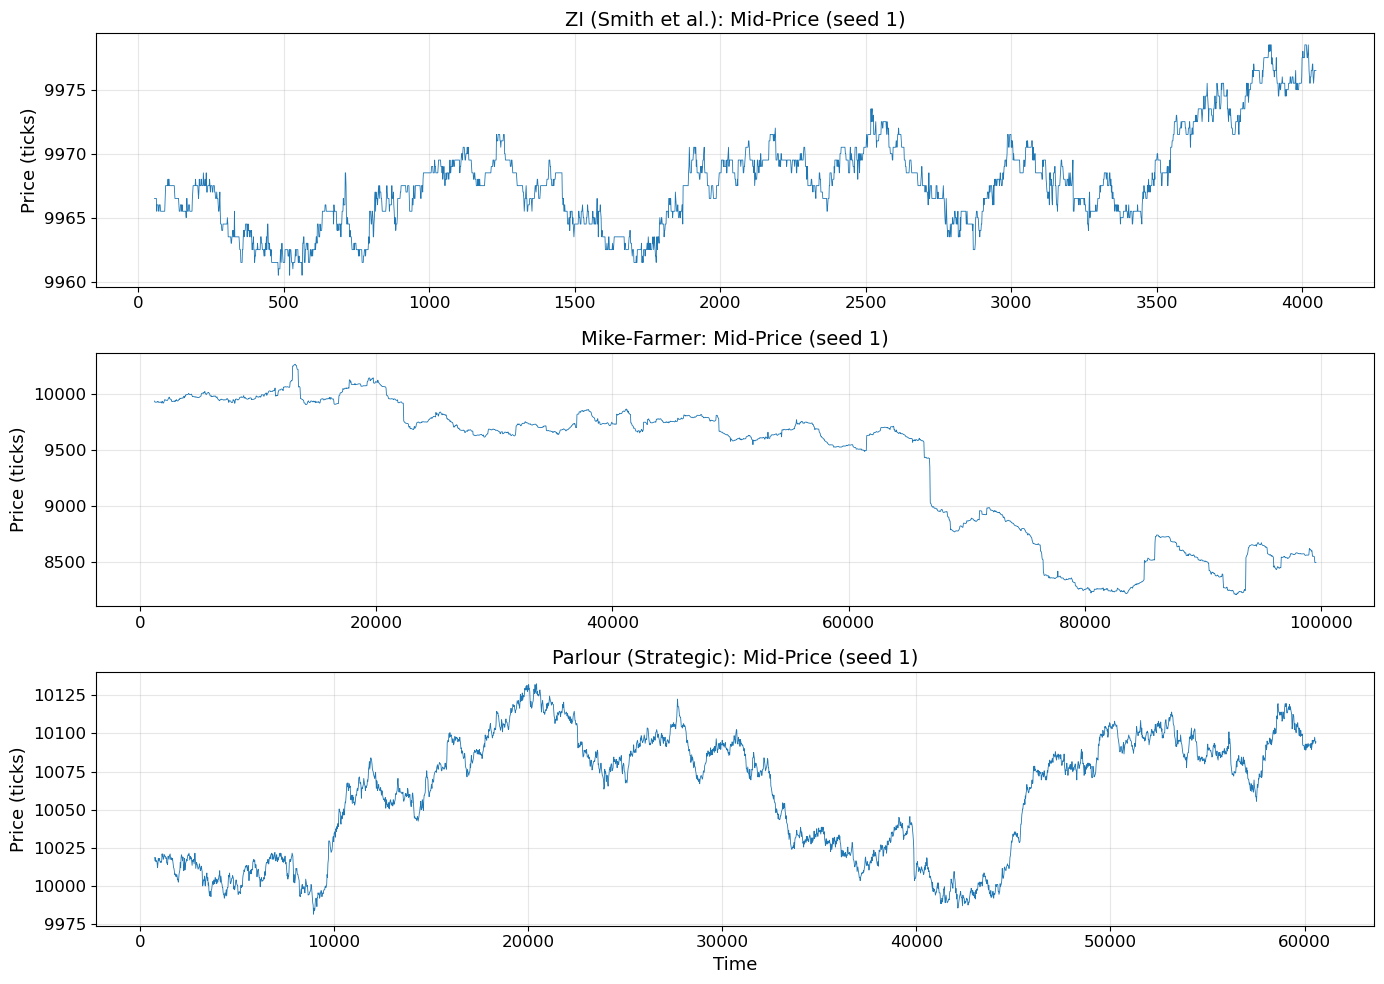

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
for ax, (name, runs) in zip(axes, results.items(), strict=True):
    v = runs[0]['df'].dropna(subset=['mid_price'])
    step = max(1, len(v) // 3000)
    ax.plot(v['time'].values[::step], v['mid_price'].values[::step], linewidth=0.6)
    ax.set_title(f'{name}: Mid-Price (seed {SEEDS[0]})')
    ax.set_ylabel('Price (ticks)')
axes[-1].set_xlabel('Time')
plt.tight_layout()
plt.show()

## 3. Returns and Volatility

The top row shows each model's return distribution (first seed) on a log scale against a fitted normal curve; the bottom row shows the autocorrelation of the ranks of $|r|$, a volatility-clustering measure that a few extreme returns cannot dominate.

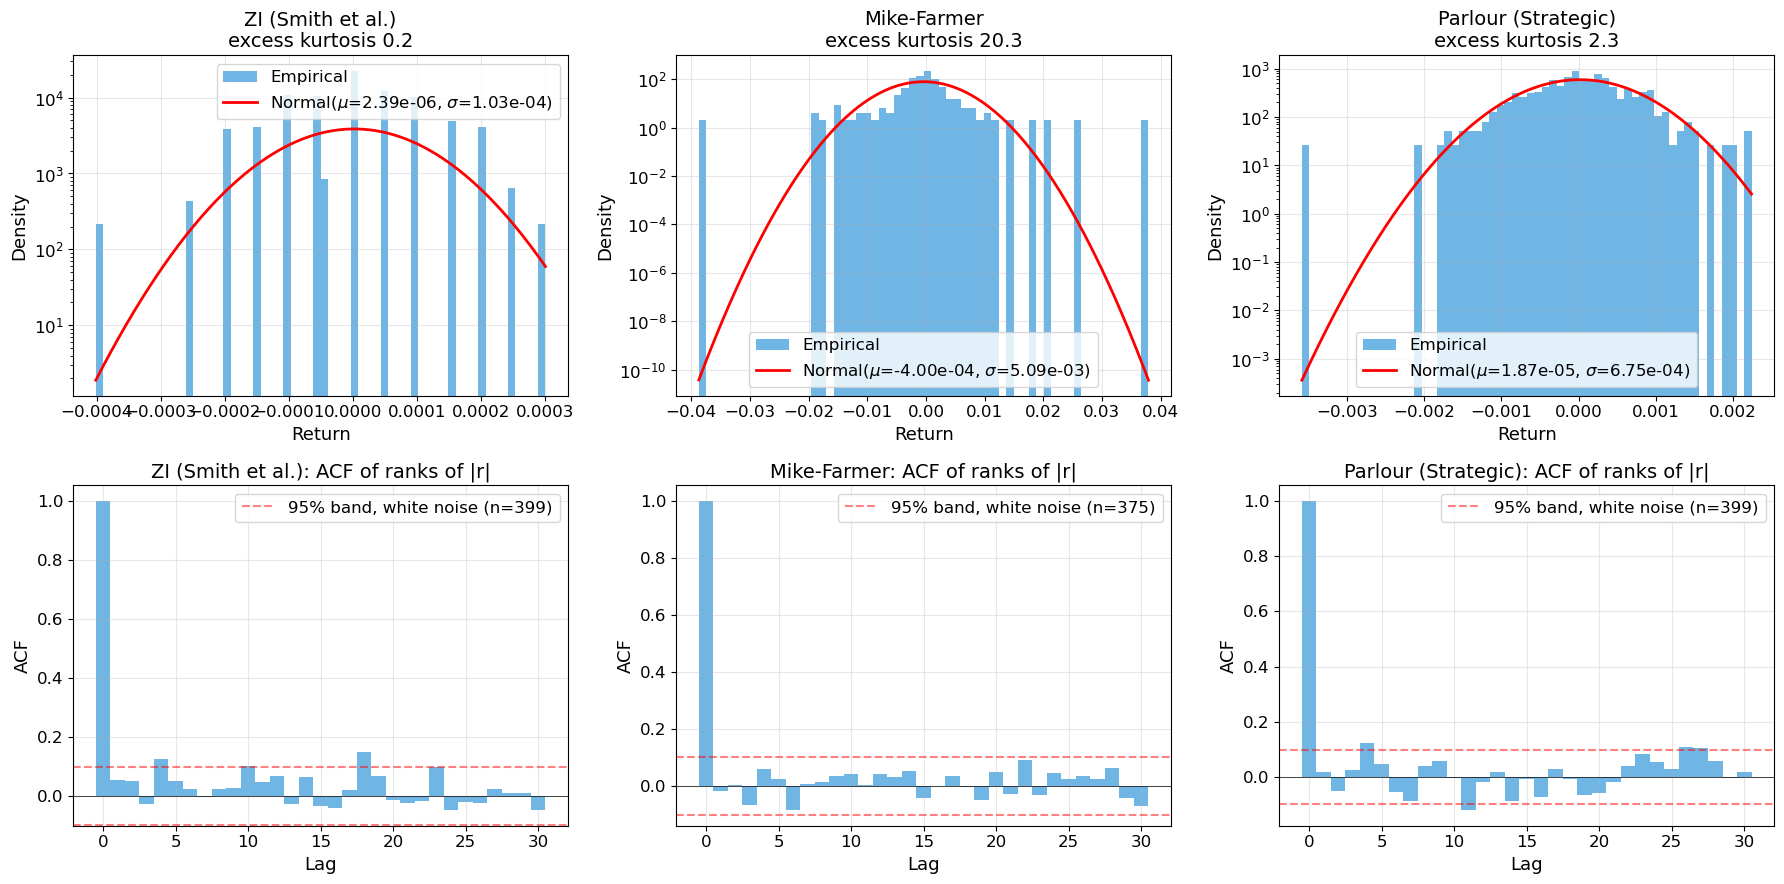

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for j, (name, runs) in enumerate(results.items()):
    r = runs[0]['returns']
    plot_return_distribution(r, n_bins=60, ax=axes[0, j])
    axes[0, j].set_title(f'{name}\nexcess kurtosis {stats.kurtosis(r):.1f}')
    plot_acf(compute_rank_volatility_acf(r, 30), title=f'{name}: ACF of ranks of |r|', ax=axes[1, j], n=len(r))
plt.tight_layout()
plt.show()

## 4. Scorecard

Each statistic is averaged over the four seeds, with its standard error (SE) across seeds. With seven facts and three models we make 21 comparisons, so a result two standard errors from its threshold can easily be chance. We therefore grade the evidence:

- **Yes**: the mean clears the threshold, in the stated direction, by more than 3 SE.
- **Weak evidence**: it clears it by 2–3 SE.
- **No**: it misses a materiality threshold (kurtosis, clustering, impact slope) by more than 2 SE.
- **Inconclusive** (threshold rows) or **Not detected** (effects that should be absent without the mechanism): anything else.

| Stylized fact | Measurement | "Yes" means |
|---|---|---|
| Heavy-tailed returns | Excess kurtosis of $K$-event log returns | above 1 |
| Volatility clustering | Lag-1 autocorrelation of the ranks of $\lvert r\rvert$ | above 0.1 |
| Long memory in order signs | Autocorrelation of buy/sell signs at lag 100 | above 0 |
| Bid-ask bounce | Lag-1 autocorrelation of trade-price changes | below 0 |
| Hump-shaped depth profile | Mean depth profile, classified as in Notebook 04 | hump |
| Concave price impact | Log-log slope of mean virtual impact (Notebook 04) | below 0.95 |

The kurtosis and clustering rows use materiality thresholds rather than zero. The book's own state changes slowly, so a small positive autocorrelation of $|r|$ can arise mechanically. Real markets show far stronger clustering that persists for weeks (Section 4.7.2), so the clustering row asks for at least 0.1.

Power-law relative prices are an input to the Mike-Farmer model rather than something it produces, so that row records how each model places orders.

In [5]:
def mean_se(values):
    values = np.asarray(values, dtype=float)
    return values.mean(), values.std(ddof=1) / np.sqrt(len(values))


def grade(margin, se, otherwise):
    """'Yes' beyond 3 SE, 'Weak evidence' at 2-3 SE, else the given fallback."""
    if margin > 3 * se:
        return 'Yes'
    if margin > 2 * se:
        return 'Weak evidence'
    return otherwise


def threshold_verdict(values, threshold, above=True):
    mean, se = mean_se(values)
    margin = mean - threshold if above else threshold - mean
    call = grade(margin, se, 'No' if margin < -2 * se else 'Inconclusive')
    return f"{call} ({mean:.3g} ± {se:.2g})"


def effect_verdict(values, positive=True):
    mean, se = mean_se(values)
    call = grade(mean if positive else -mean, se, 'Not detected')
    return f"{call} ({mean:+.3f} ± {se:.3f})"


def hump_verdict(runs):
    profile = np.mean([r['depth_profile'] for r in runs], axis=0)
    shape, rise, fall, peak = classify_depth_profile(profile)
    if shape == 'hump':
        return f"Yes (peak {peak} tick{'s' if peak != 1 else ''} out, {rise:+.0%} above the best quote)"
    return 'No (rises to a plateau)' if shape == 'plateau' else 'No (deepest at the best quote)'


def impact_verdict(runs):
    covered = min(len(r['impact_sizes']) for r in runs)
    if covered < 5:
        return f"Not measurable (90% of snapshots absorb only {covered} lot{'s' if covered != 1 else ''})"
    slopes = [fit_loglog_slope(r['impact_sizes'], r['impact']) for r in runs]
    return threshold_verdict(slopes, 0.95, above=False)


placement = {
    'ZI (Smith et al.)': 'No (uniform placement)',
    'Mike-Farmer': 'Yes (built in)',
    'Parlour (Strategic)': 'No (geometric placement)',
}

scorecard = pd.DataFrame({
    name: {
        'Mean spread (ticks)': f"{mean_se([r['mean_spread'] for r in runs])[0]:.2f}",
        'Heavy-tailed returns': threshold_verdict([r['kurtosis'] for r in runs], 1.0),
        'Volatility clustering': threshold_verdict([r['rank_acf_lag1'] for r in runs], 0.1),
        'Long memory in order signs': effect_verdict([r['sign_acf_lag100'] for r in runs]),
        'Bid-ask bounce': effect_verdict([r['bounce_acf_lag1'] for r in runs], positive=False),
        'Hump-shaped depth profile': hump_verdict(runs),
        'Concave price impact': impact_verdict(runs),
        'Power-law relative prices': placement[name],
    }
    for name, runs in results.items()
})
display(scorecard)

,ZI (Smith et al.),Mike-Farmer,Parlour (Strategic)
Mean spread (ticks),1.33,2.50,2.19
Heavy-tailed returns,No (0.252 ± 0.17),Yes (68.6 ± 21),Inconclusive (0.971 ± 0.45)
Volatility clustering,No (0.0507 ± 0.021),No (0.0105 ± 0.036),No (-0.00209 ± 0.012)
Long memory in order signs,Not detected (+0.000 ± 0.001),Yes (+0.009 ± 0.001),Not detected (-0.001 ± 0.001)
Bid-ask bounce,Yes (-0.427 ± 0.012),Yes (-0.332 ± 0.059),Yes (-0.421 ± 0.002)
Hump-shaped depth profile,No (rises to a plateau),No (deepest at the best quote),"Yes (peak 2 ticks out, +12% above the best quote)"
Concave price impact,Yes (0.898 ± 0.00062),Not measurable (90% of snapshots absorb only 2 lots),Yes (0.851 ± 0.0082)
Power-law relative prices,No (uniform placement),Yes (built in),No (geometric placement)


## 5. The Feedback Loop (Parlour Model)

The Parlour-inspired rule makes traders condition on the book: the probability of a market order rises when the spread is narrow (a limit order offers little price improvement) and when the queue at the best quotes is long (a new limit order would wait a long time). We evaluate that probability on books with a chosen spread and depth.

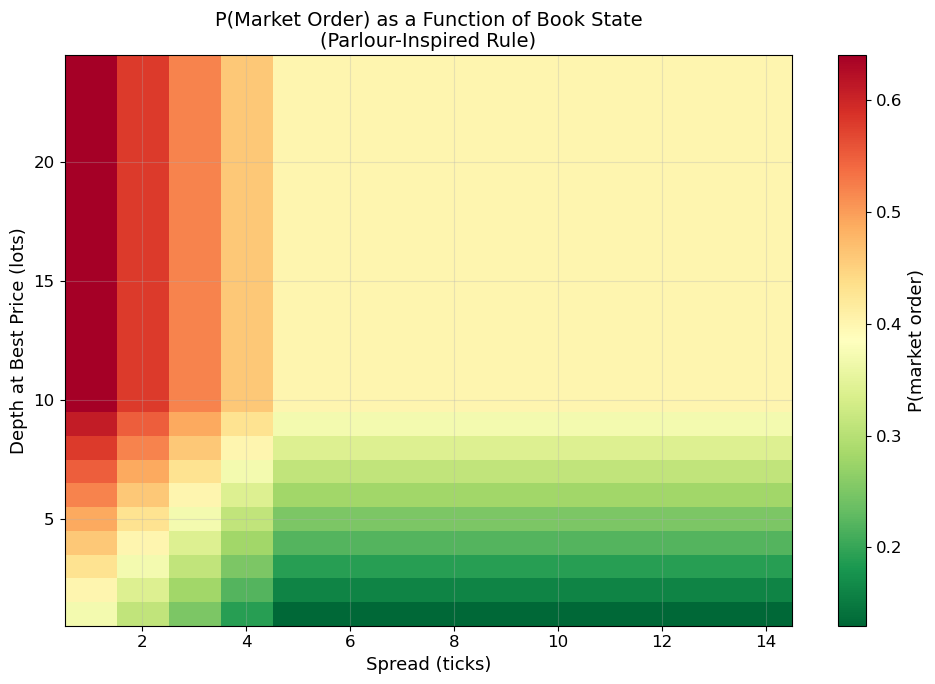

P(market order): spread 1, depth 24 -> 0.64; spread 14, depth 1 -> 0.13
Narrow spreads and long queues push traders toward market orders, which consume the queue and widen the spread, which in turn favors limit orders: the book state and the order flow feed back on each other.


In [6]:
pm = ParlourModel()
spreads_range = np.arange(1, 15)
depths_range = np.arange(1, 25)

prob_grid = np.zeros((len(depths_range), len(spreads_range)))
for i, depth in enumerate(depths_range):
    for j, spread in enumerate(spreads_range):
        reset_order_id_counter()
        book = OrderBook()
        for _ in range(depth):
            book.add_order(limit_order(10000, 1, 0.0, Side.BID))
            book.add_order(limit_order(10000 + spread, 1, 0.0, Side.ASK))
        prob_grid[i, j] = pm._prob_market_order(book)

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(prob_grid, aspect='auto', origin='lower', cmap='RdYlGn_r',
               extent=[0.5, spreads_range[-1] + 0.5, 0.5, depths_range[-1] + 0.5])
ax.set_xlabel('Spread (ticks)')
ax.set_ylabel('Depth at Best Price (lots)')
ax.set_title('P(Market Order) as a Function of Book State\n(Parlour-Inspired Rule)')
plt.colorbar(im, label='P(market order)')
plt.tight_layout()
plt.show()

narrow_deep, wide_shallow = prob_grid[-1, 0], prob_grid[0, -1]
print(f"P(market order): spread 1, depth {depths_range[-1]} -> {narrow_deep:.2f}; "
      f"spread {spreads_range[-1]}, depth 1 -> {wide_shallow:.2f}")
if narrow_deep > wide_shallow:
    print("Narrow spreads and long queues push traders toward market orders, which consume the queue and "
          "widen the spread, which in turn favors limit orders: the book state and the order flow feed back "
          "on each other.")

## Summary

The three models start from different premises: pure chance (ZI), empirically calibrated order flow (Mike-Farmer), and a rule of thumb for traders who condition on the book (Parlour). The tally below counts the stylized facts each one reproduces in these runs.

In [7]:
facts = [row for row in scorecard.index if row != 'Mean spread (ticks)']
for name in scorecard.columns:
    reproduced = [fact for fact in facts if scorecard.loc[fact, name].startswith('Yes')]
    weak = [fact for fact in facts if scorecard.loc[fact, name].startswith('Weak')]
    line = f"{name:20s} {len(reproduced)} of {len(facts)}: {', '.join(reproduced) if reproduced else 'none'}"
    if weak:
        line += f" (weak evidence: {', '.join(weak)})"
    print(line)

complete = [name for name in scorecard.columns
            if all(scorecard.loc[fact, name].startswith('Yes') for fact in facts)]
print("\nModels that reproduce every fact in the scorecard:", ', '.join(complete) if complete else 'none')

ZI (Smith et al.)    2 of 7: Bid-ask bounce, Concave price impact
Mike-Farmer          4 of 7: Heavy-tailed returns, Long memory in order signs, Bid-ask bounce, Power-law relative prices
Parlour (Strategic)  3 of 7: Bid-ask bounce, Hump-shaped depth profile, Concave price impact

Models that reproduce every fact in the scorecard: none


As the paper puts it when introducing LOB models in Section 5: *"Unsurprisingly, there is no clear consensus on the best approach."*

**Next:** Notebook 06 explores the open problems from Section 6.